In [4]:
import os

import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
import seaborn as sns

from statsmodels.tsa.api import VAR

In [5]:
#### Load Data
path_pcs = os.path.join("..", "..", "inputs", "pcs_df.csv")
pcs_df = pd.read_csv(path_pcs, index_col=0, parse_dates=True)

#### Inputs
harmonic_list = [1,2,3]

#### Path_outputs
name_model = 'var_raw_exog'
path_output = os.path.join("..", "..", "outputs", "model_comp", f"{name_model}.nc")

In [6]:
path_output

'../../outputs/model_comp/var_raw_exog.nc'

In [7]:
#### Seasonality

seasonality_df = pd.DataFrame()
seasonality_df['time'] = pcs_df.index

seasonality_df['day_of_year_frac'] = (seasonality_df.time.dt.day_of_year - 1) / 365.25
seasonality_df['year'] = seasonality_df.time.dt.year - seasonality_df.time.dt.year.min()
seasonality_df['time_num'] = seasonality_df['year'] + seasonality_df['day_of_year_frac']

seasonality_df = seasonality_df.drop(columns=['year','day_of_year_frac'])
seasonality_df = seasonality_df.set_index('time')

periods = harmonic_list

for period in periods:
    seasonality_df[f'ss_sin_{period}'] = np.sin(2*period*np.pi*seasonality_df['time_num'])
    seasonality_df[f'ss_cos_{period}'] = np.cos(2*period*np.pi*seasonality_df['time_num'])

seasonality_df = seasonality_df.drop(columns=['time_num'])

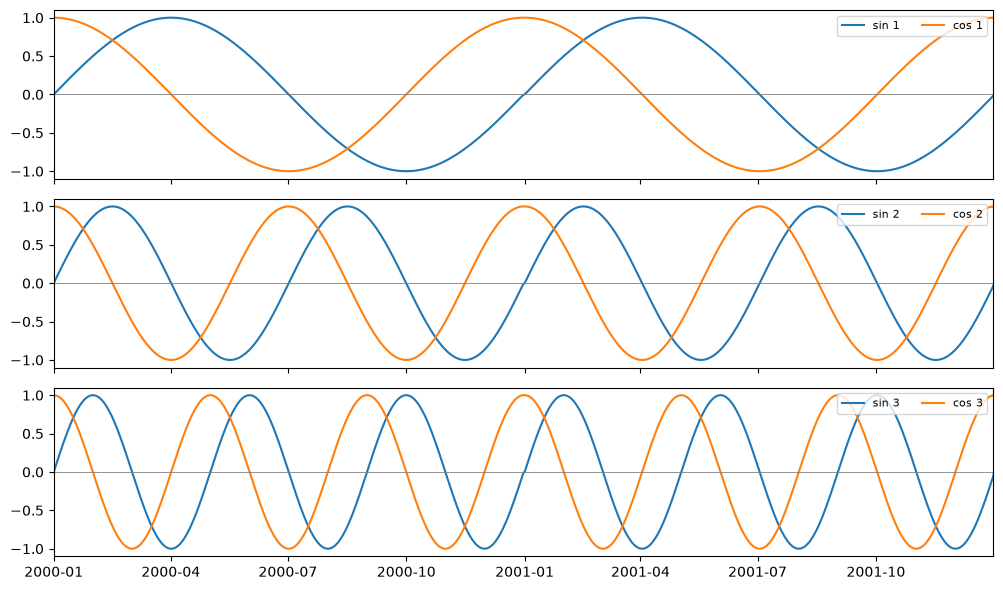

In [8]:
fig, axes = plt.subplots(len(harmonic_list), 1, figsize=(10, 2 * len(harmonic_list)), sharex=True)

for ax, h in zip(np.atleast_1d(axes), harmonic_list):
    ax.plot(seasonality_df.index, seasonality_df[f"ss_sin_{h}"], label=f"sin {h}")
    ax.plot(seasonality_df.index, seasonality_df[f"ss_cos_{h}"], label=f"cos {h}")
    ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2001-12-31"))
    ax.set_ylim(-1.1, 1.1)
    ax.axhline(0, color="grey", lw=0.6)
    ax.legend(loc="upper right", fontsize=8, ncol=2)

fig.tight_layout(); plt.show()

In [9]:
var_model = VAR(pcs_df, exog=seasonality_df, freq='D')
results = var_model.fit(maxlags=7, ic='aic', trend='c')

In [10]:
results.is_stable()

np.True_

In [11]:
best_lag = results.k_ar
print(f'Best_lag = {best_lag}')

Best_lag = 7


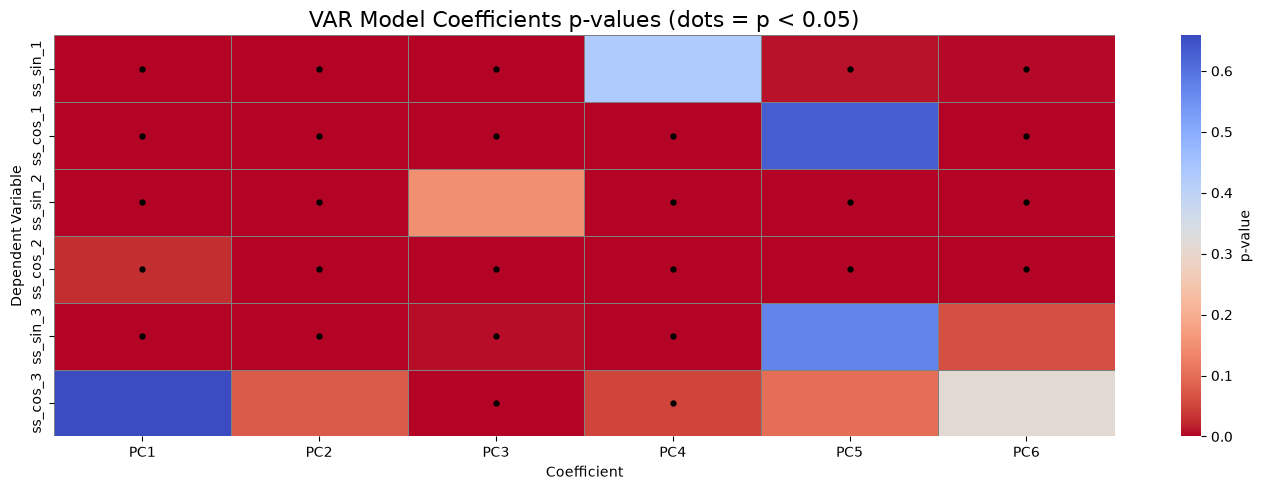

In [12]:
# p-values DataFrame
pvals = results.pvalues
covar_cols = seasonality_df.columns.to_list()
pvals_exog = pvals.loc[covar_cols]

plt.figure(figsize=(14, 5))
sns.heatmap(pvals_exog,cmap="coolwarm_r",linewidths=0.5,linecolor='gray',cbar_kws={'label': 'p-value'})

# Add black dots for significant coefficients
for i in range(pvals_exog.shape[0]):
    for j in range(pvals_exog.shape[1]):
        if pvals_exog.iloc[i, j] < 0.05:
            plt.scatter(j + 0.5, i + 0.5, color='black', s=12.5, marker='o')  # s is size

plt.title("VAR Model Coefficients p-values (dots = p < 0.05)", fontsize=16)
plt.ylabel("Dependent Variable")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

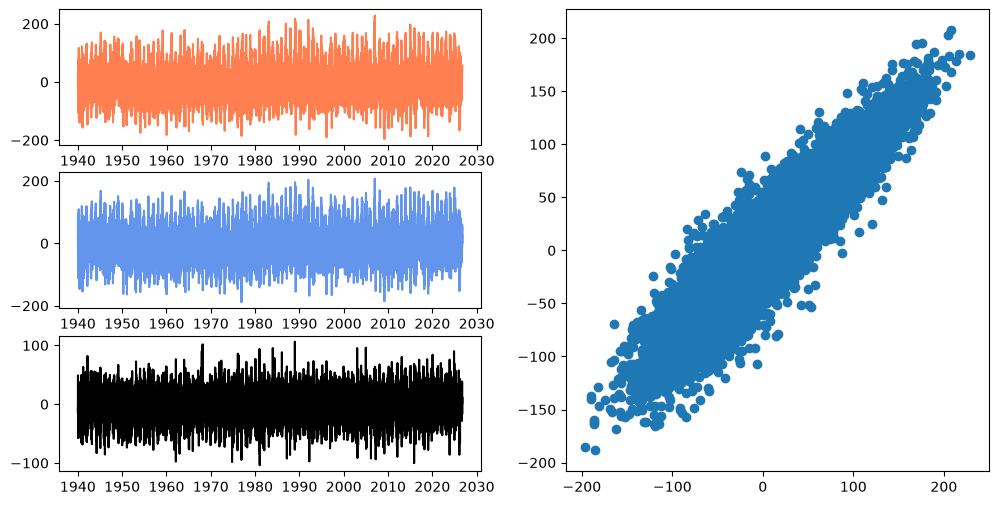

In [13]:
# Create a figure
fig = plt.figure(figsize=(12,6))

# Create a GridSpec with 2 rows and 2 columns
gs = GridSpec(3, 2)

# Add subplots to the grid
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[:, 1])


ax1.plot(pcs_df['PC1'], color='coral')
ax2.plot(results.fittedvalues['PC1'], color='cornflowerblue')
ax3.plot(results.resid['PC1'], color = 'k')

ax4.scatter(pcs_df['PC1'].values[best_lag:],results.fittedvalues['PC1'].values)

In [14]:
from sklearn.metrics import r2_score

pcs_list = pcs_df.columns.to_list()

for col in pcs_list:
    r2 = r2_score(pcs_df[col][results.fittedvalues.index], results.fittedvalues[col])
    print(f'r2 score for {col} = {r2}')

r2 score for PC1 = 0.8603564373539261
r2 score for PC2 = 0.8295688661012544
r2 score for PC3 = 0.6987751145256783
r2 score for PC4 = 0.6003909016892914
r2 score for PC5 = 0.3962228533830533
r2 score for PC6 = 0.4411219496908664


#### Predict

In [15]:
#### Covariates
n_sims = 100
BURN   = 365

# ERA5 calendar, plus BURN warm-up days before it (dropped after simulating)
sim_index = pd.date_range(start=pcs_df.index[0] - pd.Timedelta(days=BURN),
                          periods=BURN + len(pcs_df), freq='D')

In [16]:
#### Seasonality
seasonality_df_predict = pd.DataFrame()
seasonality_df_predict['time'] = sim_index

seasonality_df_predict['day_of_year_frac'] = (seasonality_df_predict.time.dt.day_of_year - 1) / 365.25
seasonality_df_predict['year'] = seasonality_df_predict.time.dt.year - seasonality_df_predict.time.dt.year.min()
seasonality_df_predict['time_num'] = seasonality_df_predict['year'] + seasonality_df_predict['day_of_year_frac']

seasonality_df_predict = seasonality_df_predict.drop(columns=['year','day_of_year_frac'])
seasonality_df_predict = seasonality_df_predict.set_index('time')

periods_seasonality = harmonic_list

for period in periods_seasonality:
    seasonality_df_predict[f'ss_sin_{period}'] = np.sin(2*period*np.pi*seasonality_df_predict['time_num'])
    seasonality_df_predict[f'ss_cos_{period}'] = np.cos(2*period*np.pi*seasonality_df_predict['time_num'])

seasonality_df_predict = seasonality_df_predict.drop(columns=['time_num'])

In [17]:
params_exog = results.params.loc[seasonality_df_predict.columns.to_list()]
n_eq = len(pcs_df.columns.to_list())

offset_df_list = []
n_sims=100
for i in range(n_sims):

    exog = pd.concat([seasonality_df_predict], axis=1)
    eq_df_list = []

    for j in range(n_eq):
        df = pd.DataFrame()
        df['time'] = exog.index.values
        for col in exog.columns.to_list():
            df[f'{pcs_df.columns.to_list()[j]}_{col}'] = params_exog[f'{pcs_df.columns.to_list()[j]}'].loc[col] * exog[col].values
        df = df.set_index('time')
        eq_df_list.append(df.copy())

    offset_df = pd.DataFrame()
    offset_df['time'] = exog.index.values

    for j in range(n_eq):
        offset_df[f'{pcs_df.columns.to_list()[j]}'] = eq_df_list[j].sum(axis=1).values + results.params.loc['const'].loc[pcs_df.columns.to_list()[j]] #+ results.params.loc['trend'][j] * (np.arange(0,len(seasonality_df_predict)) + seasonality_df.loc[seasonality_df_predict.index[0]].time_num)

    offset_df = offset_df.set_index('time')

    offset_df_list.append(offset_df.copy())

In [18]:
simulations_list = []

for sim_idx in range(n_sims):
    sim_data = results.simulate_var(steps=len(exog), offset=offset_df_list[sim_idx].values, rng=sim_idx)

    sim_df = pd.DataFrame(sim_data[BURN:], columns=pcs_df.columns, index=pcs_df.index)

    simulations_list.append(sim_df.copy())

/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-packages/statsmodels/tsa/vector_ar/var_model.py:1061: FutureWarning: After statsmodels 0.15 is released, passing an integer whencreating a random number generator will pass the value to np.random.default_rng, rather than the current behavior of passing it to np.random.RandomState. To continue using RandomState, directly pass a RandomState instance.
  rng = check_random_state(rng, deprecated=True)


In [19]:
simulations_list_xr = []

for i in simulations_list:
    simulations_list_xr.append(i.to_xarray())

sim = xr.concat(simulations_list_xr, dim='seed')
sim = sim.to_array('pc').rename({'index': 'time'}).transpose('seed', 'time', 'pc').rename('pcs')
sim.to_netcdf(path_output)

In [20]:
sim_0_df = sim.isel(seed=0).to_pandas()

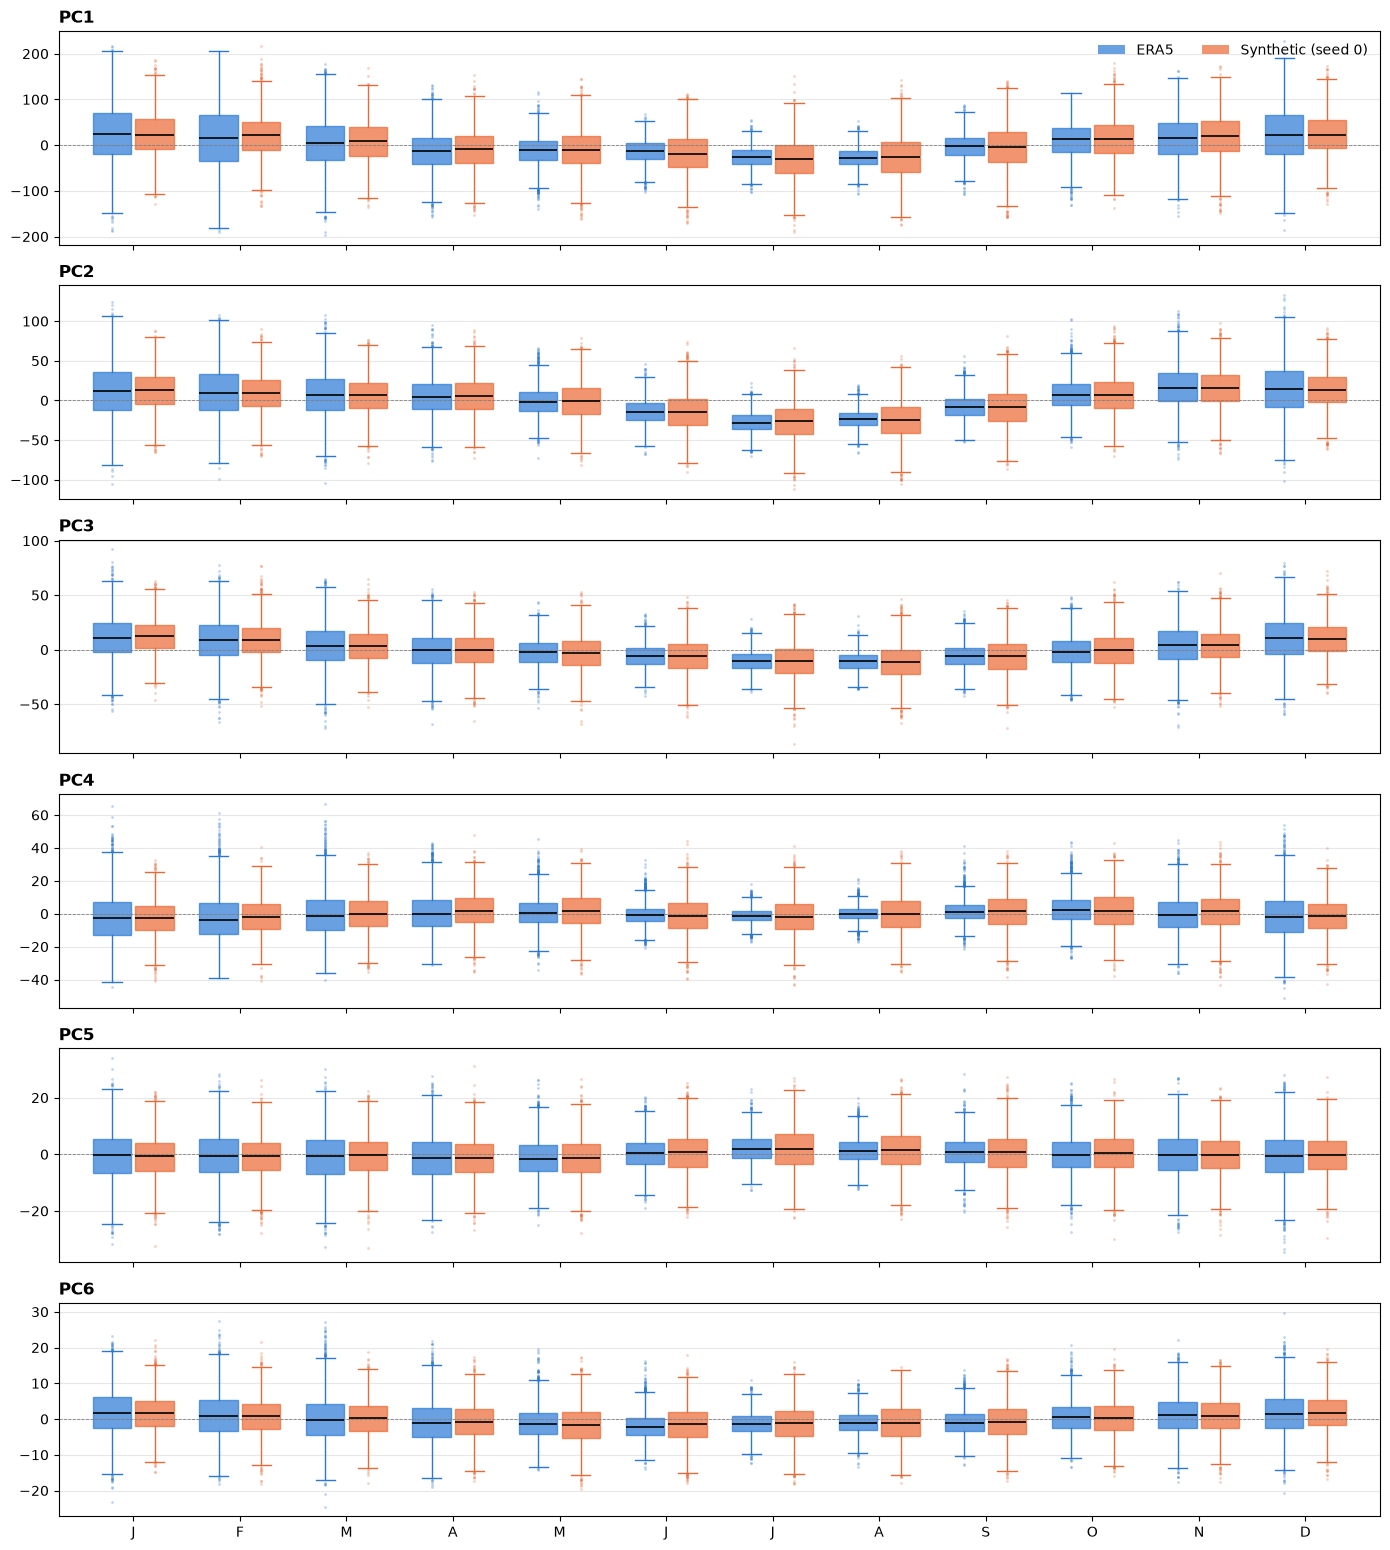

In [21]:
def monthly_boxplots(dfs, colors, pcs=None):
    """dfs: {label: DataFrame with DatetimeIndex}. One row per PC, boxes side by side per month."""
    pcs    = pcs or list(next(iter(dfs.values())).columns)
    months = np.arange(1, 13)
    n      = len(dfs)
    width  = 0.8 / n

    fig, axes = plt.subplots(len(pcs), 1, figsize=(14, 2.6 * len(pcs)), sharex=True)
    for ax, pc in zip(np.atleast_1d(axes), pcs):
        for i, (label, df) in enumerate(dfs.items()):
            data = [df.loc[df.index.month == m, pc].values for m in months]
            pos  = months - 0.4 + width * (i + 0.5)
            bp = ax.boxplot(data, positions=pos, widths=width * 0.9, patch_artist=True,
                            flierprops=dict(marker=".", markersize=2, alpha=0.3,
                                            markeredgecolor=colors[label]),
                            medianprops=dict(color="black", lw=1.2),
                            whiskerprops=dict(color=colors[label]),
                            capprops=dict(color=colors[label]))
            for box in bp["boxes"]:
                box.set(facecolor=colors[label], alpha=0.7, edgecolor=colors[label])
        ax.set_title(pc, loc="left", fontweight="bold")
        ax.axhline(0, color="grey", lw=0.6, ls="--")
        ax.grid(axis="y", alpha=0.3)
    axes[-1].set_xticks(months)
    axes[-1].set_xticklabels(list("JFMAMJJASOND"))
    axes[0].legend(handles=[Patch(facecolor=c, alpha=0.7, label=l) for l, c in colors.items()],
                   loc="upper right", ncol=n, frameon=False)
    fig.tight_layout()
    return fig

monthly_boxplots({"ERA5": pcs_df, "Synthetic (seed 0)": sim_0_df},
                 colors={"ERA5": "#2a78d6", "Synthetic (seed 0)": "#eb6834"})
plt.show()

In [26]:
from tv_var.harmonic_standardizer import HarmonicStandardizer

In [27]:
harm_std = HarmonicStandardizer(n_harmonics=3)
harm_std.fit(pcs_df)

In [28]:
def acf_by_month(df, max_lag=10):
    """{f'{pc}_month_{m}': [1, r1, ..., r_max_lag]} on the given (standardized) data."""
    auto_corr = {}
    for pc in df.columns:
        era5_aux_df = df[[pc]].copy()
        for i in range(1, max_lag + 1):
            era5_aux_df[f'{pc}_lag_{i}'] = era5_aux_df[pc].shift(i)

        era5_aux_df['month'] = era5_aux_df.index.month
        for month in range(1, 13):
            aux_df = era5_aux_df[era5_aux_df['month'] == month].drop(columns='month')
            auto_corr[f'{pc}_month_{month}'] = aux_df.corr().values[:, 0]
    return auto_corr

In [29]:
zs_df   = harm_std.transform(pcs_df)            # ERA5 on z
acf_obs = acf_by_month(zs_df)

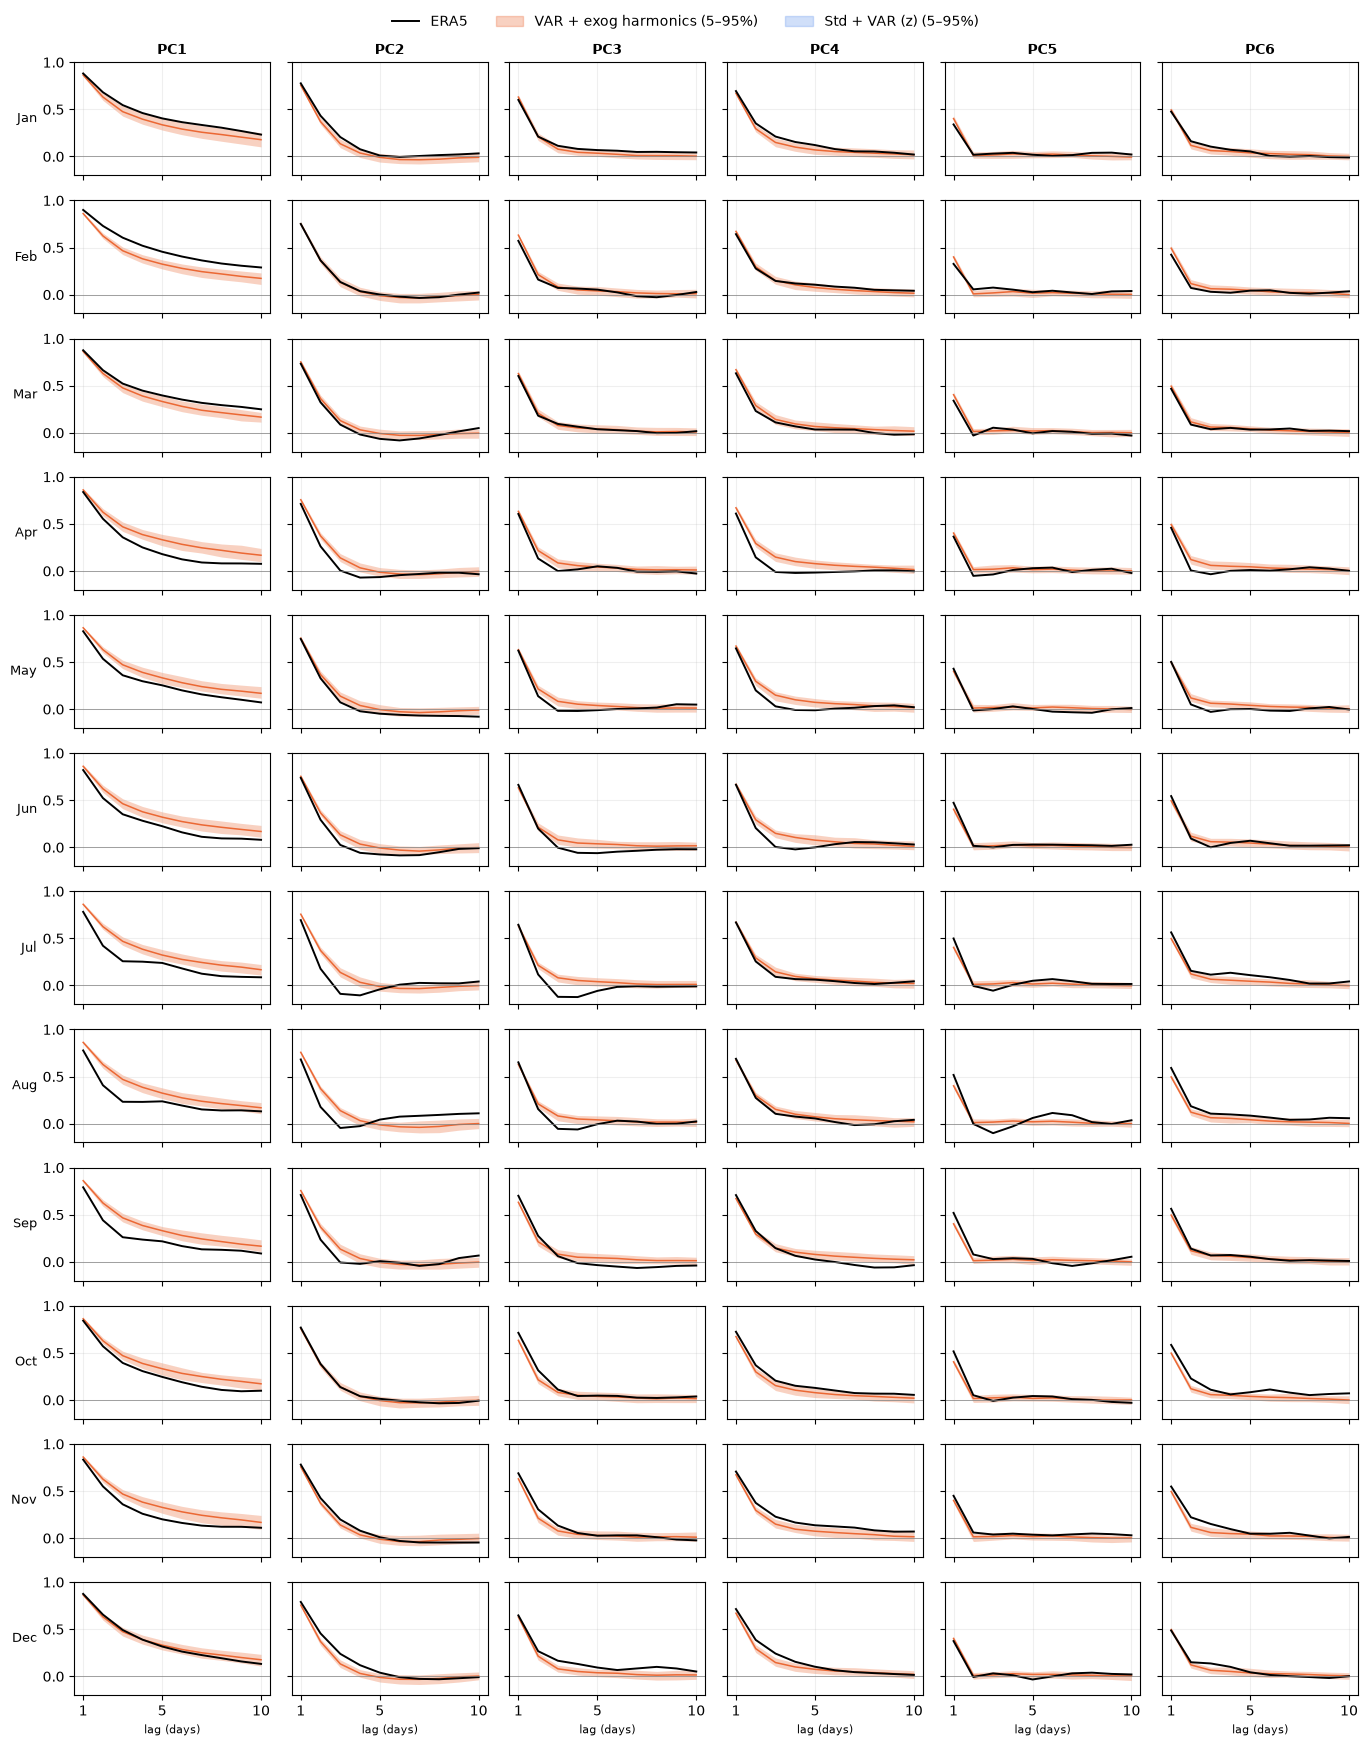

In [31]:
sim_exog = xr.open_dataarray(os.path.join("..", "..", "outputs", "model_comp", "var_raw_exog.nc"))
months = range(1, 13)
lags   = np.arange(1, 11)
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
def acf_records(sim, n=None):
    n = n or sim.sizes["seed"]
    return [acf_by_month(harm_std.transform(sim.isel(seed=s).to_pandas())) for s in range(n)]

acf_models = {
    "VAR + exog harmonics": acf_records(sim_exog),
}
colors = {"VAR + exog harmonics": "#eb6834", "Std + VAR (z)": "cornflowerblue"}

fig, axes = plt.subplots(12, len(pcs_list), figsize=(2.3 * len(pcs_list), 1.45 * 12),
                         sharex=True, sharey=True)

for i, m in enumerate(months):
    for j, pc in enumerate(pcs_list):
        ax  = axes[i, j]
        key = f'{pc}_month_{m}'
        for name, acfs in acf_models.items():
            sim = np.array([a[key][1:] for a in acfs])
            lo, hi = np.percentile(sim, [5, 95], axis=0)
            ax.fill_between(lags, lo, hi, color=colors[name], alpha=0.3, lw=0)
            ax.plot(lags, np.median(sim, axis=0), color=colors[name], lw=1.1)
        ax.plot(lags, acf_obs[key][1:], color="black", lw=1.4)
        ax.axhline(0, color="grey", lw=0.5); ax.grid(alpha=0.2)
        if i == 0: ax.set_title(pc, fontsize=10, fontweight="bold")
        if j == 0: ax.set_ylabel(month_names[m - 1], fontsize=9, rotation=0, ha="right", va="center")

axes[0, 0].set_ylim(-0.2, 1.0); axes[0, 0].set_xticks([1, 5, 10])
for ax in axes[-1]: ax.set_xlabel("lag (days)", fontsize=8)

handles = [plt.Line2D([], [], color="black", lw=1.4, label="ERA5")] + \
          [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.3, label=f"{n} (5–95%)") for n, c in colors.items()]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.005))
fig.tight_layout(rect=(0, 0, 1, 0.99)); plt.show()